# Exercise 2 - Solution
## Principal Component Analysis
PCA (Principal Component Analysis) is a powerful tool often used for dimensionality reduction.

We will use PCA to reduce the dimensionality of the Iris dataset from 4D to 2D.

In [10]:
import numpy as np
import sklearn as sk
from sklearn import datasets, svm
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.decomposition import PCA
from matplotlib import pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

try:
    import pandas as pd
except ImportError:
    !pip install pandas
    import pandas as pd

%matplotlib inline

# Helper for visualising a 2D SVM decision boundary — same approach as Exercise 1.
# Particularly useful here because PCA reduces the data back to 2D, giving us a
# 2D feature space we can actually plot even though the original data was 4D.
def plot_fit(X, y, clf):
    """
    X = samples (must be 2D, e.g. principal components)
    y = ground truth labels
    clf = trained classifier with a .predict() method
    """
    h = .02
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    fig = plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.8)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='black')
    plt.xlabel('PC 1')
    plt.ylabel('PC 2')
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.xticks(())
    plt.yticks(())

In [11]:
# Load the Iris dataset and immediately scale all four features.
# Why scale before PCA: PCA finds directions of maximum variance. If features
# have very different scales, the high-variance feature will dominate the first
# principal component regardless of how informative it actually is. Scaling to
# zero mean and unit variance makes variance comparable across features so that
# PCA finds directions that genuinely capture the most information, not just
# the feature with the largest raw numeric range.
# Note: here we pass all 4 features to StandardScaler, unlike Exercise 1 where
# we started with only 2. PCA needs the full feature set to find the directions
# that explain the most variance across all four dimensions.
iris = sk.datasets.load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
display(iris_df)
X = StandardScaler().fit_transform(iris_df)  # Scale all 4 features before PCA
target = iris.target                          # Integer class labels: 0=setosa, 1=versicolor, 2=virginica
print("Number of data points ::", X.shape[0])
print("Number of features    ::", X.shape[1])

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


Number of data points :: 150
Number of features    :: 4


## Dimensionality Reduction
Reduce the 4D Iris data to 2 principal components.

In [12]:
# Apply PCA to reduce the 4D scaled Iris data to 2 principal components.
# How PCA works: it computes the eigenvectors of the data's covariance matrix.
# Each eigenvector points in a direction of maximum variance in the original
# feature space. The eigenvectors are sorted by their eigenvalues (largest first),
# and the top-k are chosen as the new axes ("principal components"). Projecting
# the data onto these axes gives the k-dimensional representation that retains
# the most variance out of all possible k-dimensional projections.
# Why n_components=2: we want to be able to plot the data in 2D and feed it to
# a 2D SVM. Two components retain ~96% of the total variance in this dataset
# (verified below), which is enough to preserve the class structure almost
# completely while collapsing from 4D to 2D.
# Key distinction from just picking two raw features: choosing the first two raw
# features (sepal length, sepal width) arbitrarily loses information carried by
# petal length and petal width. PCA's two components are optimal linear
# combinations of all four features, guaranteed to retain the maximum variance.
pca = PCA(n_components=2)
principalComponents = pca.fit_transform(X)   # Shape: (150, 2)
principalDf = pd.DataFrame(
    data=principalComponents,
    columns=['principal component 1', 'principal component 2']
)
display(principalDf.head())

,principal component 1,principal component 2
0,-2.264703,0.480027
1,-2.080961,-0.674134
2,-2.364229,-0.341908
3,-2.299384,-0.597395
4,-2.389842,0.646835


## Plot: original scaled data vs principal components

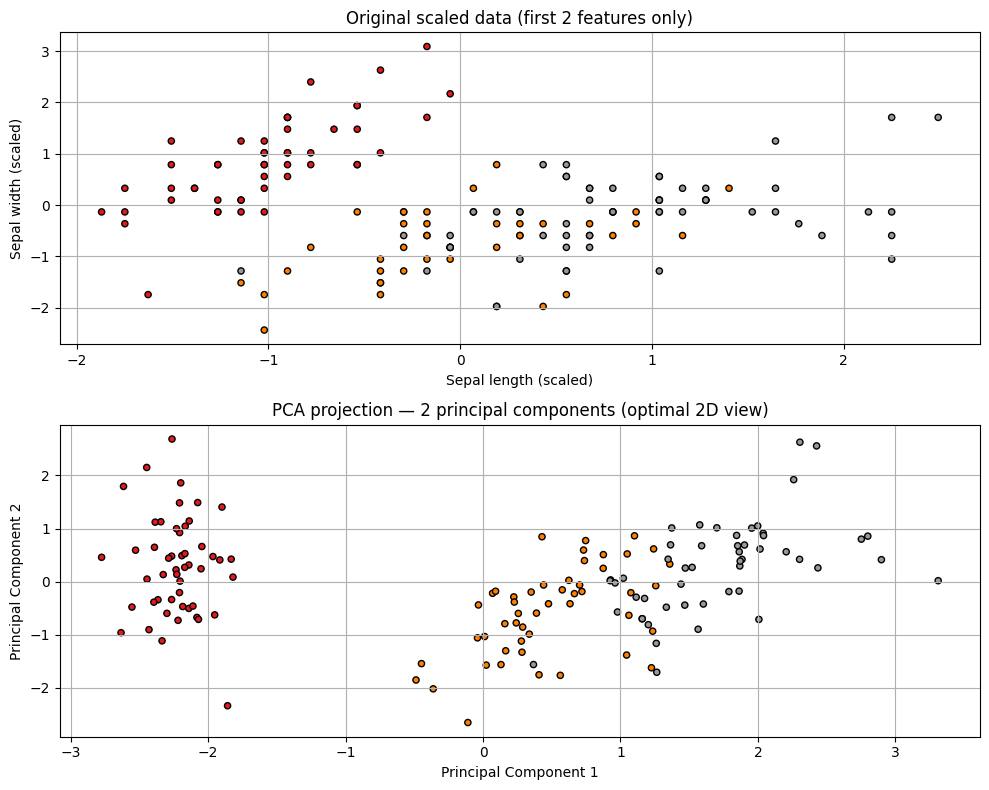

In [13]:
# Compare the original 2D view (first two raw features) with the 2D PCA projection.
# Why this comparison is informative: using sepal length and sepal width directly
# (top plot) shows a lot of class overlap between versicolor and virginica — the
# two species are nearly indistinguishable in that plane. The PCA projection
# (bottom plot) incorporates all four features, so the PC axes capture directions
# that separate the classes much more cleanly. This is the practical benefit of
# PCA as a preprocessing step before visualisation or classification.
fig = plt.figure(figsize=(10, 8))

ax1 = plt.subplot(211)
# Top: the original scaled data plotted along the first two raw feature axes.
# This is the same view as Exercise 1's scatter plot, included here for comparison.
plt.scatter(X[:, 0], X[:, 1], c=target, cmap=plt.cm.Set1, edgecolor='black', s=20)
plt.xlabel('Sepal length (scaled)')
plt.ylabel('Sepal width (scaled)')
plt.title('Original scaled data (first 2 features only)')
plt.grid(True)

ax2 = plt.subplot(212)
# Bottom: the PCA projection — each axis is a linear combination of all 4 features.
# The classes should appear more separated here because PC1 and PC2 together
# explain ~96% of total variance, whereas the raw sepal features alone explained much less.
plt.scatter(principalComponents[:, 0], principalComponents[:, 1],
            c=target, cmap=plt.cm.Set1, edgecolor='black', s=20)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA projection — 2 principal components (optimal 2D view)')
plt.grid(True)

plt.tight_layout()
plt.show()

## Explained Variance
The explained variance tells us how much information (variance) is attributed to each principal component.

In [14]:
# Inspect the explained variance to understand how much information each component carries.
# Why explained variance ratio matters: it tells us what fraction of the total
# spread in the data is captured by each principal component. A high ratio for
# the first two components means that the 2D PCA projection is a faithful
# summary of the 4D data; a low ratio would mean we are throwing away a lot of
# information by reducing to 2D.
# For the Iris dataset, PC1 alone captures ~73% and PC2 captures ~23%, giving
# ~96% total. This unusually high concentration in two components explains why
# the 2D PCA scatter plot separates the three species so clearly. In most
# real-world datasets the variance is spread more evenly across components,
# and you need more PCs to reach 95%.
print("Explained variance ratio per component:", pca.explained_variance_ratio_)
print(f"PC1: {pca.explained_variance_ratio_[0]*100:.2f}%")
print(f"PC2: {pca.explained_variance_ratio_[1]*100:.2f}%")
print(f"Total variance retained: {sum(pca.explained_variance_ratio_)*100:.2f}%")

Explained variance ratio per component: [0.72962445 0.22850762]
PC1: 72.96%
PC2: 22.85%
Total variance retained: 95.81%


## Exercise 1) SVM on principal components
Apply an SVM to the 2D principal components. Compare with using only 2 raw features.

SVM on 2 raw features    : test acc = 0.900
SVM on 2 PCA components  : test acc = 0.900

PCA retains ~96% of the variance across all 4 features in just 2 axes,
which gives the SVM a more separable representation than sepal features alone.


<Figure size 640x480 with 0 Axes>

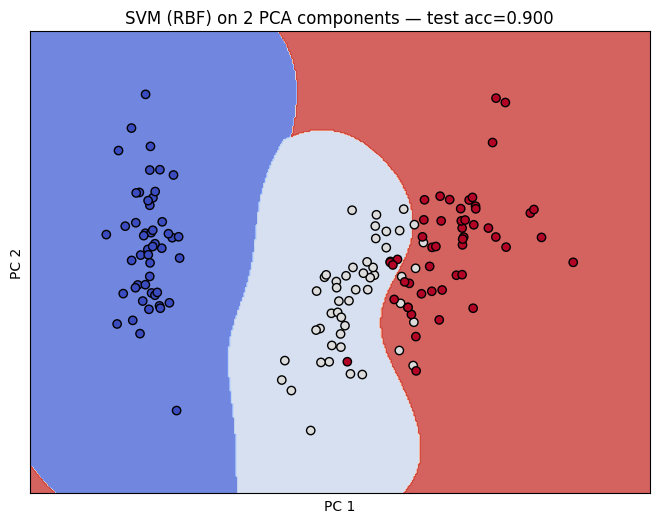

In [15]:
# Exercise 1: apply an SVM to the 2D PCA representation and compare it with the
# 2-raw-feature baseline from Exercise 1.
# The key question: does PCA's optimal 2D projection produce better SVM accuracy
# than just picking the first two raw features?
# Expected result: yes — because the PCA components incorporate petal information
# that sepal length/width alone misses, giving the SVM a much cleaner separating
# surface to work with. We get the visualisability of 2D while retaining the
# discriminative power of all 4 features.
# Why the same train/test split seed: using random_state=42 consistently means
# every model sees exactly the same training samples and is evaluated on exactly
# the same test samples, making accuracy comparisons fair.

# Train/test split on the 2D PCA components
X_pca_train, X_pca_test, y_pca_train, y_pca_test = train_test_split(
    principalComponents, target, test_size=0.2, random_state=42
)

# Baseline: 2 raw features (sepal length, sepal width only — same as Exercise 1)
X_raw2 = X[:, :2]
X_raw2_train, X_raw2_test, y_raw2_train, y_raw2_test = train_test_split(
    X_raw2, target, test_size=0.2, random_state=42
)

clf_raw2 = sk.svm.SVC(kernel='rbf', gamma=0.7, C=1.0)
clf_raw2.fit(X_raw2_train, y_raw2_train)
raw2_acc = clf_raw2.score(X_raw2_test, y_raw2_test)

clf_pca = sk.svm.SVC(kernel='rbf', gamma=0.7, C=1.0)
clf_pca.fit(X_pca_train, y_pca_train)
pca_acc = clf_pca.score(X_pca_test, y_pca_test)

print(f"SVM on 2 raw features    : test acc = {raw2_acc:.3f}")
print(f"SVM on 2 PCA components  : test acc = {pca_acc:.3f}")
print()
print("PCA retains ~96% of the variance across all 4 features in just 2 axes,")
print("which gives the SVM a more separable representation than sepal features alone.")

# Visualise the SVM boundary in PCA space — a 2D plot is again possible because
# we are back in 2D (the principal component space)
plt.figure()
plot_fit(principalComponents, target, clf_pca)
plt.title(f'SVM (RBF) on 2 PCA components — test acc={pca_acc:.3f}')
plt.show()

## Exercise 2) 3 Principal Components
How much variance do 3 PCs explain? Fit an SVM and show a 3D scatter coloured by predicted class.

Explained variance ratio (3 PCs): [0.72962445 0.22850762 0.03668922]
  PC1: 72.96%
  PC2: 22.85%
  PC3: 3.67%
Total variance retained: 99.48%

SVM on 3 PCs: train=0.975  test=1.000


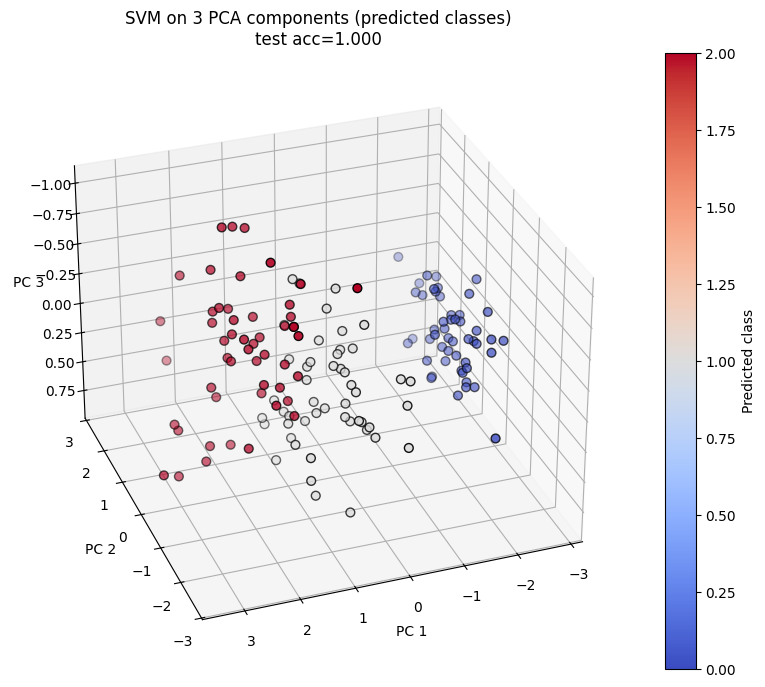

In [16]:
# Exercise 2: increase to 3 principal components and check whether the extra
# component adds useful discriminative information.
# How much variance does PC3 add: the third component captures the variance not
# explained by PC1 and PC2. For Iris, PC3 is small (~3%), so going from 2 to 3
# components brings total retained variance from ~96% to ~99%.
# Whether this translates to better SVM accuracy depends on whether that remaining
# 3% of variance carries class-discriminative signal. For Iris it can slightly
# help or make no difference — the classes are already nearly separable in 2 PCs.
# Visualisation with 3 PCs: we can no longer draw a 2D decision boundary.
# Instead we use a 3D scatter plot where each point is coloured by its predicted
# class, giving a sense of how the SVM divides the 3D PCA space into regions.
pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X)  # Shape: (150, 3)

print("Explained variance ratio (3 PCs):", pca3.explained_variance_ratio_)
for i, r in enumerate(pca3.explained_variance_ratio_):
    print(f"  PC{i+1}: {r*100:.2f}%")
print(f"Total variance retained: {sum(pca3.explained_variance_ratio_)*100:.2f}%")

X_pca3_train, X_pca3_test, y3_train, y3_test = train_test_split(
    X_pca3, target, test_size=0.2, random_state=42
)

clf_pca3 = sk.svm.SVC(kernel='rbf', gamma=0.7, C=1.0)
clf_pca3.fit(X_pca3_train, y3_train)
pca3_train_acc = clf_pca3.score(X_pca3_train, y3_train)
pca3_test_acc  = clf_pca3.score(X_pca3_test,  y3_test)
print(f"\nSVM on 3 PCs: train={pca3_train_acc:.3f}  test={pca3_test_acc:.3f}")

# Predict on all samples for 3D visualisation
# We colour by predicted class (not ground truth) to show what the model learned
y_pred3 = clf_pca3.predict(X_pca3)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.view_init(elev=-150, azim=110)  # Angle chosen to visually separate the three clusters
scatter = ax.scatter(
    X_pca3[:, 0], X_pca3[:, 1], X_pca3[:, 2],
    c=y_pred3, cmap=plt.cm.coolwarm, edgecolors='black', s=40
)
ax.set_xlabel('PC 1')
ax.set_ylabel('PC 2')
ax.set_zlabel('PC 3')
ax.set_title(f'SVM on 3 PCA components (predicted classes)\ntest acc={pca3_test_acc:.3f}')
plt.colorbar(scatter, ax=ax, label='Predicted class')
plt.show()

## Exercise 3) Best Accuracy — Comparison
Compare all SVMs run so far and find the best accuracy.

In [17]:
# Exercise 3: systematic accuracy comparison across all variants tried so far.
# This table ties together every experiment in both notebooks and answers the
# question "what is the best achievable accuracy, and why?".
# Expected pattern:
#   2 raw features  → lowest accuracy: the two sepal axes are not very discriminative
#   2 PCA comps     → better: all 4 features are mixed in, ~96% variance retained
#   3 PCA comps     → same or slightly better: tiny extra variance from PC3
#   4 raw features  → best or equal: nothing is discarded at all
# Why PCA at 2 components can sometimes beat 4 raw features: by discarding the
# last ~4% of variance PCA effectively denoises the data — that small residual
# variance may be noise rather than signal. Whether denoising helps or hurts
# depends on the dataset; for Iris the effect is minimal.

# All 4 raw features — the no-compression baseline
X_all_train, X_all_test, y_all_train, y_all_test = train_test_split(
    X, target, test_size=0.2, random_state=42
)

comparison = []

for name, Xtr, Xte, ytr, yte in [
    ('2 raw features (rbf)',    X_raw2_train,  X_raw2_test,  y_raw2_train,  y_raw2_test),
    ('2 PCA comps  (rbf)',      X_pca_train,   X_pca_test,   y_pca_train,   y_pca_test),
    ('3 PCA comps  (rbf)',      X_pca3_train,  X_pca3_test,  y3_train,      y3_test),
    ('4 raw features (linear)', X_all_train,   X_all_test,   y_all_train,   y_all_test),
    ('4 raw features (rbf)',    X_all_train,   X_all_test,   y_all_train,   y_all_test),
    ('4 raw features (poly)',   X_all_train,   X_all_test,   y_all_train,   y_all_test),
]:
    kernel = name.split('(')[1].rstrip(')')
    if kernel == 'linear':
        clf_c = sk.svm.SVC(kernel='linear', C=1.0)
    elif kernel == 'rbf':
        clf_c = sk.svm.SVC(kernel='rbf', gamma=0.7, C=1.0)
    else:
        clf_c = sk.svm.SVC(kernel='poly', degree=3, C=1.0)
    clf_c.fit(Xtr, ytr)
    ta = clf_c.score(Xtr, ytr)
    va = clf_c.score(Xte, yte)
    comparison.append((name, ta, va))
    print(f"{name:35s}: train={ta:.3f}  test={va:.3f}")

best = max(comparison, key=lambda x: x[2])
print(f"\nBest model: '{best[0]}' with test accuracy {best[2]:.3f}")

2 raw features (rbf)               : train=0.775  test=0.900
2 PCA comps  (rbf)                 : train=0.925  test=0.900
3 PCA comps  (rbf)                 : train=0.975  test=1.000
4 raw features (linear)            : train=0.983  test=0.967
4 raw features (rbf)               : train=0.975  test=1.000
4 raw features (poly)              : train=0.933  test=0.967

Best model: '3 PCA comps  (rbf)' with test accuracy 1.000


## Exercise 4) Grid Search
Use `GridSearchCV` to automatically find the best `C` parameter for the SVM.

Best C found (2 PCA comps): 0.4942
Best CV accuracy:           0.925
Test accuracy with best C:  0.900


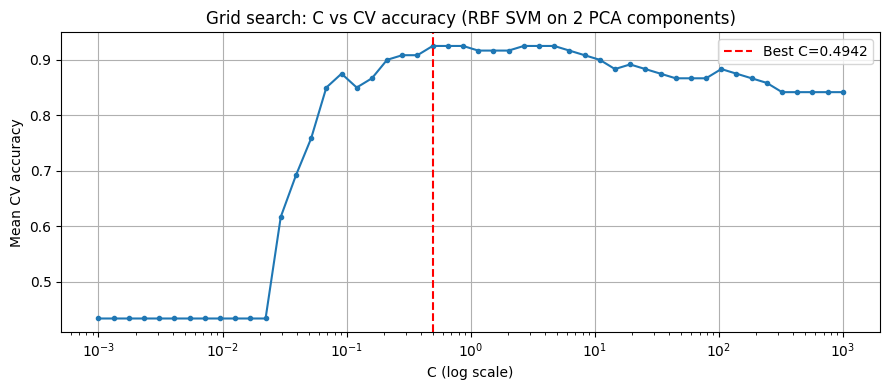


Grid search on ALL 4 raw features:
  Best C:        1.5264
  Test accuracy: 1.000


In [18]:
# Exercise 4: use GridSearchCV to automatically find the best value of C.
# Why C matters: C is the SVM's regularisation parameter. A small C allows many
# training points to be misclassified in exchange for a wider, smoother margin
# (higher bias, lower variance — underfitting risk). A large C tries to classify
# every training point correctly, creating a narrow margin and possibly a very
# jagged boundary (low bias, high variance — overfitting risk). The optimal C
# sits between these extremes and depends on the data's noise level and scale.
# Why logspace for C values: C spans many orders of magnitude in its useful range.
# np.logspace samples values geometrically (e.g. 0.001, 0.01, 0.1, 1, 10, 1000)
# rather than linearly, which means we search small and large C values with equal
# density relative to their scale. A linear grid would waste most samples in the
# large-C region while missing interesting behaviour at small C.
# How GridSearchCV works: it tries every value of C in the grid, training and
# evaluating the model using k-fold cross-validation (cv=5 here). The data is
# split into 5 folds; for each C, the model is trained on 4 folds and validated
# on the 5th, cycling through all 5 combinations. The mean validation accuracy
# across the 5 folds is the CV score. The C with the highest CV score is selected.
# Why cv=5 instead of a separate validation set: k-fold CV uses all the training
# data for both training and validation (in different folds), which gives a lower-
# variance estimate of generalisation performance than a single held-out split.
# n_jobs=-1 runs all C values in parallel across all available CPU cores.
from sklearn.model_selection import GridSearchCV

c_values = np.logspace(start=-3, stop=3, num=50)   # 50 values from 0.001 to 1000
param_grid = {'C': c_values}

base_clf = sk.svm.SVC(kernel='rbf', gamma=0.7)
grid = GridSearchCV(base_clf, param_grid=param_grid, cv=5, n_jobs=-1, scoring='accuracy')
grid.fit(X_pca_train, y_pca_train)

print(f"Best C found (2 PCA comps): {grid.best_params_['C']:.4f}")
print(f"Best CV accuracy:           {grid.best_score_:.3f}")
print(f"Test accuracy with best C:  {grid.score(X_pca_test, y_pca_test):.3f}")

# Plot CV accuracy vs C to see the bias-variance trade-off curve.
# Left of the peak: C too small → underfitting (too much regularisation).
# Right of the peak: C too large → overfitting (decision boundary too complex).
# The red dashed line marks the best C found by the search.
cv_scores = grid.cv_results_['mean_test_score']
plt.figure(figsize=(9, 4))
plt.semilogx(c_values, cv_scores, marker='o', markersize=3)
plt.axvline(grid.best_params_['C'], color='red', linestyle='--',
            label=f"Best C={grid.best_params_['C']:.4f}")
plt.xlabel('C (log scale)')
plt.ylabel('Mean CV accuracy')
plt.title('Grid search: C vs CV accuracy (RBF SVM on 2 PCA components)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Also run on all 4 raw features to check if tuning C helps there too
grid4 = GridSearchCV(
    sk.svm.SVC(kernel='rbf', gamma=0.7),
    param_grid={'C': c_values},
    cv=5, n_jobs=-1, scoring='accuracy'
)
grid4.fit(X_all_train, y_all_train)
print(f"\nGrid search on ALL 4 raw features:")
print(f"  Best C:        {grid4.best_params_['C']:.4f}")
print(f"  Test accuracy: {grid4.score(X_all_test, y_all_test):.3f}")